# 07 — What does the learned condition embedding encode?

Question: has CellFlow's condition encoder organised cytokines by **receptor family**, and if so, did it
learn that during training or inherit it from the ESM2 protein embeddings it is fed?

**Model:** `models/06_baseline_CellFlow.pkl`, trained in `06_baseline.ipynb` (500k iterations, IL-15 held out
for Donor1/2/12). Notebook 01 is the GPU inventory and saved no model; 06 is the only trained model in this repo.

**Method**
1. `cf.get_condition_embedding(covariate_data, rep_dict, condition_id_key)` on all 20 trained cytokines.
   The encoder pools the cytokine token with the **donor** token (`pool_sample_covariates=True`), so each
   condition is a *(cytokine, donor)* pair. We embed every cytokine under each of the 4 donors and analyse
   each donor separately plus the donor-averaged embedding.
2. `plot_condition_embedding`, coloured by `obs['cytokine_family']`.
3. Silhouette score (cosine) with `cytokine_family` as labels vs 100 label permutations. Families with a single
   cytokine among the 20 cannot form a cluster (sklearn gives them silhouette 0 by definition), so the score is
   computed on cytokines whose family has ≥2 members here; the singleton cytokines are dropped.
4. The same on the raw 2560-d ESM2 vectors (the encoder's input).
5. Shared-receptor groups: within-group vs between-group cosine distance in both spaces.

**Caveat for step 5:** of the 13 cytokines in the four receptor groups, only **IL-6** and **IFN-epsilon** are in
the 20-cytokine training subset (`DATA.md`). All 13 have ESM2 vectors in `uns['esm2_embeddings']`, so the others
are passed through the trained encoder **zero-shot**. Their learned embedding is a function of ESM2 that the
model never received a training signal for. Step 5 is therefore mostly a test of what the encoder does to
ESM2, not of what training taught it about those specific proteins.

Kernel: `cellflow`, CPU. Part I takes seconds. Part II reads the full dataset once (cached afterwards), so run it on a compute node: `sbatch scripts/run_07_condition_embedding.sbatch`.

In [1]:
import os
os.environ.setdefault("JAX_PLATFORMS", "cpu")

import warnings
warnings.simplefilter("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.spatial.distance import pdist, squareform
from scipy.stats import spearmanr
from sklearn.metrics import silhouette_score, silhouette_samples
import time
from IPython.display import display
from sklearn.decomposition import KernelPCA

from cellflow.model import CellFlow
from cellflow.plotting import plot_condition_embedding

MODEL_PATH = "../models/06_baseline_CellFlow.pkl"
N_PERM = 100
SEED = 0

RECEPTOR_GROUPS = {
    "CSF1R": ["M-CSF", "IL-34"],
    "IFNAR": ["IFN-alpha1", "IFN-beta", "IFN-epsilon", "IFN-omega"],
    "gp130": ["IL-6", "IL-11", "LIF", "OSM", "CT-1"],
    "IL17RA/RC": ["IL-17A", "IL-17F"],
}

## Load the model and the cytokine metadata

In [2]:
cf = CellFlow.load(MODEL_PATH)
obs = cf.adata.obs

treated = obs[~obs["is_control"]]
TRAINED = sorted(treated["cytokine"].unique())
DONORS = sorted(obs["donor"].unique())
family = treated.drop_duplicates("cytokine").set_index("cytokine")["cytokine_family"].astype(str).loc[TRAINED]

esm2 = {k: np.asarray(v) for k, v in cf.adata.uns["esm2_embeddings"].items()}
ALL_CYTOKINES = sorted(esm2)

print(len(TRAINED), "trained cytokines;", len(ALL_CYTOKINES), "cytokines with ESM2 vectors; donors:", DONORS)
missing = [c for g in RECEPTOR_GROUPS.values() for c in g if c not in esm2]
assert not missing, missing
family.value_counts().rename("n_cytokines").to_frame()

20 trained cytokines; 93 cytokines with ESM2 vectors; donors: ['Donor1', 'Donor12', 'Donor2', 'Donor8']


,n_cytokines
cytokine_family,
Common γ chain/IL-13/TSLP,8
TNF,2
IL-6/IL-12,2
Growth factor,2
Other,1
Complement,1
Interferon,1
Common β chain,1
IL-17,1


## 1. Extract condition embeddings

`covariate_data` needs the columns used at training (`cytokine`, `donor`, `is_control`); `rep_dict` supplies
the ESM2 and donor vectors. `var` is 0 everywhere because the model is `condition_mode="deterministic"`.

In [3]:
cov = pd.DataFrame([(c, d) for d in DONORS for c in ALL_CYTOKINES], columns=["cytokine", "donor"])
cov["is_control"] = False
cov["condition"] = cov["donor"] + "|" + cov["cytokine"]

rep_dict = {k: cf.adata.uns[k] for k in ["esm2_embeddings", "donor_embeddings"]}
emb_mean, emb_var = cf.get_condition_embedding(
    covariate_data=cov, rep_dict=rep_dict, condition_id_key="condition", key_added=None
)
print(emb_mean.shape, "| max |var|:", float(np.abs(emb_var.values).max()))

# learned[space] -> DataFrame (cytokine x 256), one per donor plus the donor average
learned = {d: emb_mean.loc[[f"{d}|{c}" for c in ALL_CYTOKINES]].set_axis(ALL_CYTOKINES) for d in DONORS}
learned["donor-mean"] = sum(learned[d] for d in DONORS) / len(DONORS)

esm2_df = pd.DataFrame(np.stack([esm2[c] for c in ALL_CYTOKINES]), index=ALL_CYTOKINES)
# ESM2 vectors share a large common component (median pairwise cosine distance ~0.05), which dominates raw
# cosine. The centred version (mean over all 93 cytokines removed) is reported as a sensitivity check.
esm2_centred = esm2_df - esm2_df.mean()

SPACES = {"ESM2 (raw)": esm2_df, "ESM2 (centred)": esm2_centred, **{f"learned {k}": v for k, v in learned.items()}}

[                                        ] | 0% Completed | 166.05 us

[########################################] | 100% Completed | 101.25 ms

[                                        ] | 0% Completed | 86.76 us

[########################################] | 100% Completed | 101.30 ms

[                                        ] | 0% Completed | 176.11 us

[########################################] | 100% Completed | 103.06 ms

(372, 256) | max |var|: 0.0


How much does the donor move a cytokine's embedding? Cosine distance between the same cytokine under two
donors, compared with the distance between two different cytokines under the same donor (20 trained cytokines).

In [4]:
same_cyt = [pdist(np.stack([learned[a].loc[c], learned[b].loc[c]]), "cosine")[0]
            for c in TRAINED for i, a in enumerate(DONORS) for b in DONORS[i + 1:]]
diff_cyt = np.concatenate([pdist(learned[d].loc[TRAINED].values, "cosine") for d in DONORS])
rank_corr = pd.DataFrame(
    [[spearmanr(pdist(learned[a].loc[TRAINED].values, "cosine"), pdist(learned[b].loc[TRAINED].values, "cosine"))[0]
      for b in DONORS] for a in DONORS], index=DONORS, columns=DONORS)
print(f"same cytokine, different donor: median cosine distance {np.median(same_cyt):.3f}")
print(f"different cytokine, same donor: median cosine distance {np.median(diff_cyt):.3f}")
print("Spearman correlation of the cytokine-cytokine distance matrices between donors:")
rank_corr.round(2)

same cytokine, different donor: median cosine distance 0.699
different cytokine, same donor: median cosine distance 0.605
Spearman correlation of the cytokine-cytokine distance matrices between donors:


,Donor1,Donor12,Donor2,Donor8
Donor1,1.00,0.63,0.61,0.68
Donor12,0.63,1.00,0.70,0.73
Donor2,0.61,0.70,1.00,0.70
Donor8,0.68,0.73,0.70,1.00


## 2. Plot, coloured by cytokine family

2-D cosine kernel-PCA of each space, passed to `plot_condition_embedding(embedding="raw_embedding")`. (The helper's
own `"PCA"`/`"Kernel_PCA"` options request 30 components, which is more than the 20 points here.)

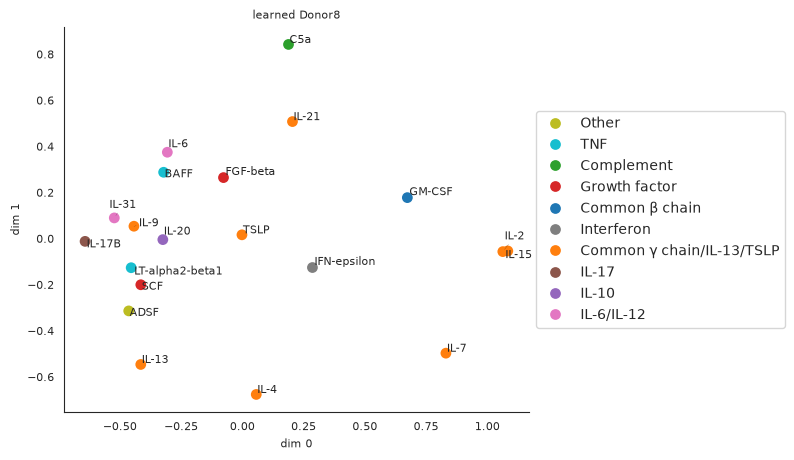

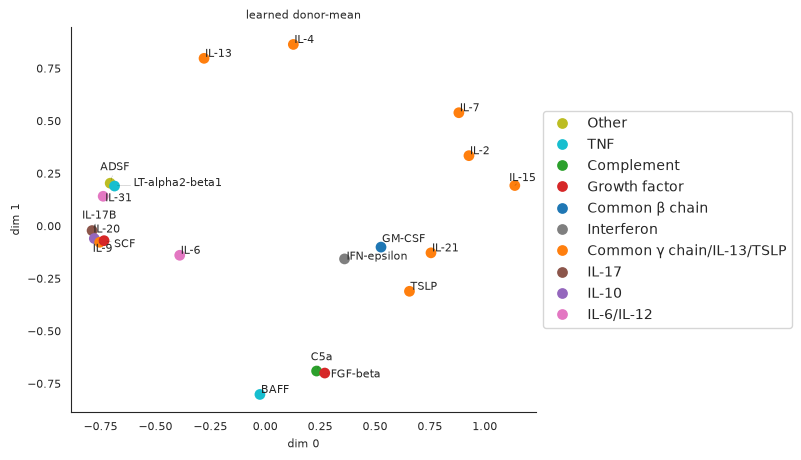

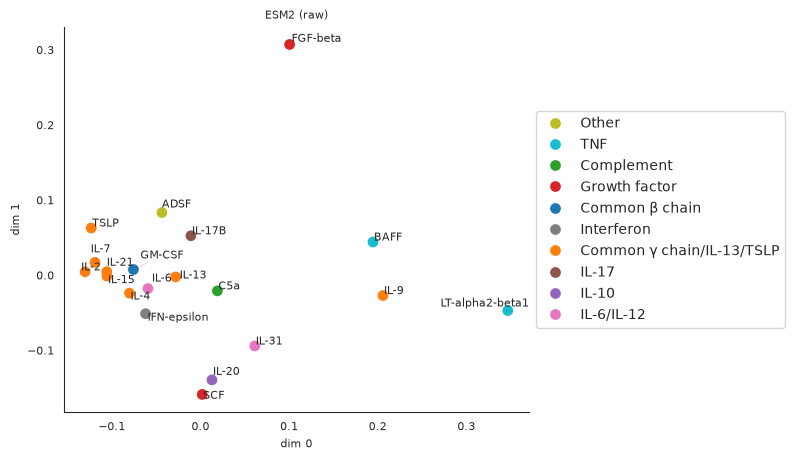

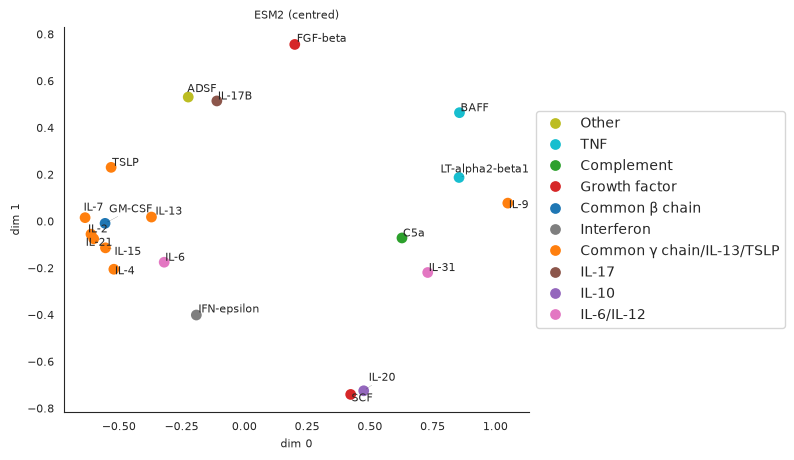

In [5]:
families = sorted(family.unique())
palette = dict(zip(families, sns.color_palette("tab10", len(families)).as_hex()))


def plot_space(name, X):
    Z = KernelPCA(n_components=2, kernel="precomputed").fit_transform(1 - squareform(pdist(X.values, "cosine")))
    df = pd.DataFrame(Z, index=X.index, columns=[0, 1])
    df["cytokine_family"] = family.loc[X.index].values
    df["cytokine"] = X.index
    fig = plot_condition_embedding(
        df, embedding="raw_embedding", hue="cytokine_family", labels="cytokine", col_dict=palette,
        title=name, fig_width=6, fig_height=5, circle_size=60, fontsize=8,
    )
    plt.show()


for name in ["learned Donor8", "learned donor-mean", "ESM2 (raw)", "ESM2 (centred)"]:
    plot_space(name, SPACES[name].loc[TRAINED])

## 3–4. Silhouette vs label permutations, learned and ESM2 spaces

Empirical p-value = (1 + #{permuted ≥ observed}) / (1 + N_PERM). Labels are permuted among the same cytokines,
so the family sizes stay fixed.

In [6]:
multi = family[family.map(family.value_counts()) >= 2]
print(f"silhouette computed on {len(multi)} cytokines in {multi.nunique()} families; "
      f"dropped singletons: {sorted(set(TRAINED) - set(multi.index))}")


def silhouette_test(X, labels, n_perm=N_PERM, seed=SEED):
    D = squareform(pdist(X, "cosine"))
    obs_s = silhouette_score(D, labels, metric="precomputed")
    rng = np.random.default_rng(seed)
    null = np.array([silhouette_score(D, rng.permutation(labels), metric="precomputed") for _ in range(n_perm)])
    return obs_s, null


sil_rows, nulls = [], {}
for name, X in SPACES.items():
    s, null = silhouette_test(X.loc[multi.index].values, multi.values)
    nulls[name] = null
    sil_rows.append({"space": name, "silhouette": s, "perm_mean": null.mean(), "perm_95%": np.quantile(null, 0.95),
                     "p_empirical": (1 + (null >= s).sum()) / (1 + N_PERM)})
sil = pd.DataFrame(sil_rows).set_index("space")
sil.round(3)

silhouette computed on 14 cytokines in 4 families; dropped singletons: ['ADSF', 'C5a', 'GM-CSF', 'IFN-epsilon', 'IL-17B', 'IL-20']


,silhouette,perm_mean,perm_95%,p_empirical
space,,,,
ESM2 (raw),0.097,-0.237,0.020,0.040
ESM2 (centred),0.139,-0.192,0.028,0.020
learned Donor1,-0.128,-0.220,-0.059,0.158
learned Donor12,-0.207,-0.212,-0.065,0.416
learned Donor2,-0.030,-0.210,-0.028,0.069
learned Donor8,-0.296,-0.236,-0.057,0.733
learned donor-mean,-0.117,-0.208,-0.046,0.168


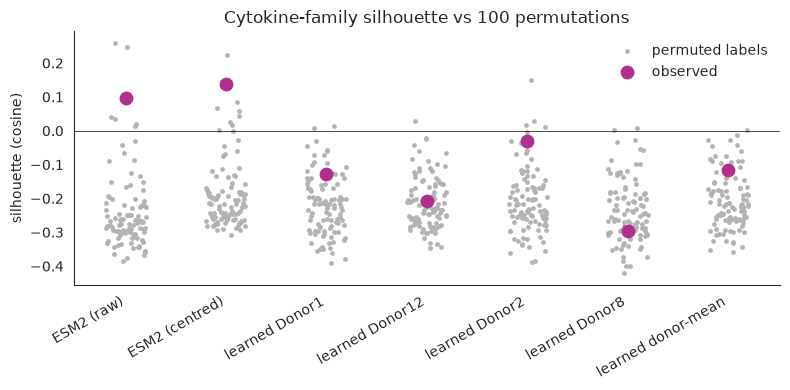

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
order = list(SPACES)
for i, name in enumerate(order):
    ax.scatter(np.full(N_PERM, i) + np.random.default_rng(i).uniform(-0.2, 0.2, N_PERM), nulls[name],
               s=6, color="0.7", label="permuted labels" if i == 0 else None)
    ax.scatter(i, sil.loc[name, "silhouette"], s=80, color="#B12F8C", zorder=3, label="observed" if i == 0 else None)
ax.axhline(0, color="k", lw=0.5)
ax.set_xticks(range(len(order)), order, rotation=30, ha="right")
ax.set_ylabel("silhouette (cosine)")
ax.set_title("Cytokine-family silhouette vs 100 permutations")
ax.legend(frameon=False)
sns.despine()
plt.tight_layout()
plt.show()

The silhouette is driven mostly by the 8-member common-γ-chain family (the subset was built around IL-15's
family). Per-family mean silhouette, to see which families actually cohere:

In [8]:
per_fam = {}
for name, X in SPACES.items():
    D = squareform(pdist(X.loc[multi.index].values, "cosine"))
    per_fam[name] = pd.Series(silhouette_samples(D, multi.values, metric="precomputed"), index=multi.index) \
        .groupby(multi.values).mean()
pd.DataFrame(per_fam).T.round(3)

,Common γ chain/IL-13/TSLP,Growth factor,IL-6/IL-12,TNF
ESM2 (raw),0.361,-0.507,-0.295,0.036
ESM2 (centred),0.360,-0.402,-0.360,0.295
learned Donor1,0.036,-0.482,-0.141,-0.419
learned Donor12,-0.173,-0.387,0.283,-0.651
learned Donor2,-0.043,-0.400,0.727,-0.368
learned Donor8,-0.220,-0.467,-0.447,-0.275
learned donor-mean,0.025,-0.495,0.255,-0.677


## 5. Shared-receptor groups

For each group *G*: **within** = mean pairwise cosine distance among members of *G*; **between** = mean cosine
distance from members of *G* to the 20 trained cytokines that are not in *G*. Ratio < 1 means the group is tighter than
its distance to everything else. **Percentile** = where *within* falls among 1000 random groups of the same size
drawn from all 93 cytokines. A low percentile means the members are unusually close, so 5% is a nominal cutoff,
with 4 groups × several spaces and no correction.

In [9]:
def group_stats(X, members, ref, n_rand=1000, seed=SEED):
    D = pd.DataFrame(squareform(pdist(X.values, "cosine")), index=X.index, columns=X.index)
    within = D.loc[members, members].values[np.triu_indices(len(members), 1)].mean()
    others = [c for c in ref if c not in members]
    between = D.loc[members, others].values.mean()
    rng = np.random.default_rng(seed)
    rand = []
    for _ in range(n_rand):
        g = rng.choice(X.index, size=len(members), replace=False)
        rand.append(D.loc[g, g].values[np.triu_indices(len(g), 1)].mean())
    return within, between, 100 * (np.array(rand) <= within).mean()


rows = []
for gname, members in RECEPTOR_GROUPS.items():
    for name, X in SPACES.items():
        w, b, pct = group_stats(X, members, TRAINED)
        rows.append({"group": gname, "space": name, "within": w, "between": b, "ratio": w / b, "percentile": pct,
                     "trained_members": ", ".join(m for m in members if m in TRAINED) or "none"})
groups = pd.DataFrame(rows)
groups.pivot(index="group", columns="space", values="ratio").loc[list(RECEPTOR_GROUPS), list(SPACES)].round(2)

space,ESM2 (raw),ESM2 (centred),learned Donor1,learned Donor12,learned Donor2,learned Donor8,learned donor-mean
group,,,,,,,
CSF1R,0.44,0.40,0.15,0.35,0.59,0.38,0.40
IFNAR,0.36,0.41,0.28,0.48,0.34,0.62,0.45
gp130,0.50,0.61,0.12,0.34,0.31,0.23,0.21
IL17RA/RC,0.13,0.17,0.02,0.04,0.07,0.02,0.02


In [10]:
groups.pivot(index="group", columns="space", values="percentile").loc[list(RECEPTOR_GROUPS), list(SPACES)].round(1)

space,ESM2 (raw),ESM2 (centred),learned Donor1,learned Donor12,learned Donor2,learned Donor8,learned donor-mean
group,,,,,,,
CSF1R,10.8,4.3,17.4,18.8,46.8,30.3,28.3
IFNAR,0.0,0.0,15.5,17.6,13.0,48.0,16.1
gp130,0.3,0.4,1.3,3.1,4.4,1.8,1.4
IL17RA/RC,0.4,0.3,0.2,0.1,1.0,0.0,0.1


In [11]:
groups.set_index(["group", "space"])[["within", "between", "ratio", "percentile", "trained_members"]].round(3)

within  between  ratio  percentile  \
group     space                                                    
CSF1R     ESM2 (raw)           0.023    0.053  0.439        10.8   
          ESM2 (centred)       0.429    1.068  0.402         4.3   
          learned Donor1       0.088    0.574  0.154        17.4   
          learned Donor12      0.166    0.469  0.353        18.8   
          learned Donor2       0.237    0.401  0.591        46.8   
          learned Donor8       0.200    0.523  0.383        30.3   
          learned donor-mean   0.327    0.821  0.399        28.3   
IFNAR     ESM2 (raw)           0.018    0.050  0.357         0.0   
          ESM2 (centred)       0.405    0.991  0.409         0.0   
          learned Donor1       0.171    0.613  0.279        15.5   
          learned Donor12      0.271    0.562  0.483        17.6   
          learned Donor2       0.176    0.520  0.339        13.0   
          learned Donor8       0.374    0.603  0.620        48.0   
          learned donor-mean   0.401    0.893  0.449        16.1   
gp130     ESM2 (raw)           0.023    0.046  0.498         0.3   
          ESM2 (centred)       0.603    0.993  0.607         0.4   
          learned Donor1       0.081    0.659  0.123         1.3   
          learned Donor12      0.190    0.563  0.338         3.1   
          learned Donor2       0.137    0.441  0.312         4.4   
          learned Donor8       0.138    0.598  0.230         1.8   
          learned donor-mean   0.174    0.847  0.206         1.4   
IL17RA/RC ESM2 (raw)           0.006    0.045  0.126         0.4   
          ESM2 (centred)       0.158    0.948  0.167         0.3   
          learned Donor1       0.014    0.641  0.021         0.2   
          learned Donor12      0.019    0.504  0.038         0.1   
          learned Donor2       0.027    0.360  0.074         1.0   
          learned Donor8       0.011    0.544  0.021         0.0   
          learned donor-mean   0.017    0.792  0.022         0.1   

                             trained_members  
group     space                               
CSF1R     ESM2 (raw)                    none  
          ESM2 (centred)                none  
          learned Donor1                none  
          learned Donor12               none  
          learned Donor2                none  
          learned Donor8                none  
          learned donor-mean            none  
IFNAR     ESM2 (raw)             IFN-epsilon  
          ESM2 (centred)         IFN-epsilon  
          learned Donor1         IFN-epsilon  
          learned Donor12        IFN-epsilon  
          learned Donor2         IFN-epsilon  
          learned Donor8         IFN-epsilon  
          learned donor-mean     IFN-epsilon  
gp130     ESM2 (raw)                    IL-6  
          ESM2 (centred)                IL-6  
          learned Donor1                IL-6  
          learned Donor12               IL-6  
          learned Donor2                IL-6  
          learned Donor8                IL-6  
          learned donor-mean            IL-6  
IL17RA/RC ESM2 (raw)                    none  
          ESM2 (centred)                none  
          learned Donor1                none  
          learned Donor12               none  
          learned Donor2                none  
          learned Donor8                none  
          learned donor-mean            none

Does training change the geometry, or does the encoder mostly preserve ESM2's? Spearman correlation between the
cytokine–cytokine cosine distance matrices of ESM2 and the learned space, over the 20 trained cytokines and over
all 93.

In [12]:
corr = []
for name in ["ESM2 (raw)", "ESM2 (centred)"]:
    for subset, idx in [("20 trained", TRAINED), ("all 93", ALL_CYTOKINES)]:
        corr.append({"ESM2": name, "cytokines": subset,
                     "spearman vs learned donor-mean": spearmanr(pdist(SPACES[name].loc[idx].values, "cosine"),
                                                                 pdist(learned["donor-mean"].loc[idx].values, "cosine"))[0]})
pd.DataFrame(corr).round(3)

,ESM2,cytokines,spearman vs learned donor-mean
0,ESM2 (raw),20 trained,-0.060
1,ESM2 (raw),all 93,0.019
2,ESM2 (centred),20 trained,0.087
3,ESM2 (centred),all 93,0.308


## Conclusion — Part I (embeddings)

**No. The model has not rediscovered receptor structure.** Where receptor structure shows up in the learned space, it
was already in ESM2 and was carried through the encoder. It does not come from training.

What the numbers say:

1. **ESM2 already groups cytokines by family.** On the 14 cytokines whose family has ≥2 members here, ESM2's family
   silhouette is 0.10 (raw) / 0.14 (centred), above all but a few of 100 label permutations (p = 0.04 / 0.02). The signal
   comes almost entirely from the common-γ-chain family (IL-2, -4, -7, -9, -13, -15, -21, TSLP), whose members sit together.
2. **Training weakens that structure.** In the learned condition embedding the family silhouette is negative and not
   distinguishable from permuted labels for any donor (p = 0.07–0.73; donor-average p = 0.17). The common-γ-chain family
   no longer clusters (per-family silhouette 0.36 in ESM2 vs −0.22 to 0.04 learned).
3. **The learned geometry is mostly not ESM2's geometry.** Rank correlation between the cytokine–cytokine distance
   matrices of ESM2 and the learned space is about 0 for the 20 trained cytokines (−0.06 raw, 0.09 centred). The encoder
   rearranges cytokines a lot, just not by family.
4. **The donor matters as much as the cytokine.** The same cytokine under two donors is *farther apart* (median cosine
   distance 0.70) than two different cytokines under the same donor (0.61). Much of what the condition embedding
   encodes is the donor. That fits CellFlow pooling the donor token into the condition.
5. **Shared-receptor groups** (percentile of within-group distance among random groups of the same size; low = tight):
   * **IL-17A / IL-17F**: very tight in ESM2 (0.4th percentile) and in every learned space (0–1st). Neither cytokine
     was trained on, so this tightness **cannot have been learned**. The two proteins are close homologues, and the
     encoder passes their similarity through.
   * **gp130 (IL-6, IL-11, LIF, OSM, CT-1)**: tight in ESM2 (0.3rd) and still fairly tight learned (1–4th). Only IL-6
     was trained, so again this is inherited from ESM2.
   * **IFNAR (IFN-α1, -β, -ε, -ω)**: the tightest group in ESM2 (0th percentile), but **looser after the encoder**
     (13th–48th). Only IFN-ε was trained. The encoder partly scrambles a relationship that ESM2 had.
   * **CSF1R (M-CSF, IL-34)**: not tight in either space (4th–47th). These two ligands share a receptor but have no
     sequence similarity, so ESM2 has no way to see the link, and nothing in training taught it either.

**Plain-language summary.** The protein language model already "knows" some receptor families, the ones whose ligands
are related in sequence (IL-17A/F, the interferons, gp130 cytokines, the γ-chain family). CellFlow's learned embedding
keeps some of that and loses some, and adds no receptor structure of its own. The clearest test is CSF1R: the two
ligands look unrelated in sequence but act through the same receptor, and the model does not put them together.

**Why this is a weak test, and what would make it stronger.** The model was trained on only 20 cytokines: 8 from one
family, 6 singletons, and just 2 of the 13 receptor-group members. It never saw the responses that would let it learn
that M-CSF and IL-34, or IL-6 and OSM, do the same thing to cells. A fair test of "rediscovery" needs a model trained
on all ~90 cytokines, with the receptor groups in the training set. Then run the same notebook on it. The donor
effect in (4) also suggests comparing embeddings after regressing out donor, or with `pool_sample_covariates=False`.

# Part II — Does the *biology* have receptor structure?

Parts 1–5 asked whether the model's embedding groups cytokines by family. That is only a meaningful failure if the
cells themselves respond in a family-structured way. Here the same machinery (cosine silhouette vs 100 label
permutations; within- vs between-group distance for the four shared-receptor groups) is applied to the
**measured responses**.

**Response vector.** For each donor *d*, cytokine *c* and cell type *t*: pseudobulk delta =
mean log1p(CP10k) of (*c*, *d*, *t*) cells − mean of (PBS, *d*, *t*) cells, over the 2,000 HVGs. Deltas are averaged over
the donors where both sides have ≥ 20 cells. A cytokine's response vector is the concatenation of its per-cell-type
deltas over the cell types available for every cytokine, so each cell type counts equally.

**Data:** the full dataset already on disk (`pbmc_parse.h5ad`, 90 cytokines, 12 donors). The group means are computed
once in a chunked pass and cached (`data/cellflow/pbmc_parse_pseudobulk_log1p_means.h5ad`), so this part must run on
a compute node the first time.

**Comparisons**
* **A. The same 14 cytokines as in part 3** (the 20 trained cytokines, families with ≥2 members). This is a like-for-like
  comparison with the embedding results above.
* **B. All 90 cytokines.** The labels are `cytokine_family` for families with ≥2 members, excluding the catch-all bins
  "Other" and "Interleukin - non-classified", which are not receptor families. ESM2 and the learned embedding are
  scored on the same cytokines; 70 of the 90 are zero-shot for the model, as in part 5.
* **C. Shared-receptor groups** in response space, with all 13 members measured. The reference set and random
  groups are drawn from the 90 cytokines, and ESM2 and the learned embedding are rescored the same way.
* **Reliability.** A cytokine with almost no effect has a response vector that is mostly noise, and noise does not
  cluster. The split-half correlation of each response vector (donors 1–6 vs 7–12) is reported, and B is repeated on
  the reliably responding cytokines.

In [13]:
import h5py
import anndata as ad
import scipy.sparse as sp

FULL_PATH = "/fast/AG_Bunina/Pavel_1/data/cellflow/hf_cache/hub/datasets--theislab--cellflow-datasets/snapshots/4b235c9a1e0073c95211c6ef6257db184fc83f71/pbmc_parse.h5ad"
PB_CACHE = "/fast/AG_Bunina/Pavel_1/data/cellflow/pbmc_parse_pseudobulk_log1p_means.h5ad"
MIN_CELLS_PB = 20
CATCH_ALL = {"Other", "Interleukin - non-classified"}
RELIABLE_R = 0.5


def _decode(a):
    return [x.decode() if isinstance(x, bytes) else str(x) for x in a]


def pseudobulk_means(path, chunk=500_000):
    # mean log1p(CP10k over the 2000 HVGs) per (cytokine, donor, cell_type); one sequential pass over X
    with h5py.File(path, "r") as f:
        cols = ["cytokine", "donor", "cell_type"]
        obs = pd.DataFrame({c: pd.Categorical.from_codes(f["obs"][c]["codes"][:], _decode(f["obs"][c]["categories"][:]))
                            for c in cols})
        fam = f["obs"]["cytokine_family"]
        fam = pd.Categorical.from_codes(fam["codes"][:], _decode(fam["categories"][:]))
        cyt_family = pd.Series(np.asarray(fam, dtype=object), index=obs["cytokine"].astype(str)).groupby(level=0).first()
        g = obs.groupby(cols, observed=True)
        gid, keys = g.ngroup().to_numpy(), g.size()
        genes = _decode(f["var"]["_index"][:])
        indptr = f["X"]["indptr"][:]
        sums = np.zeros((len(keys), len(genes)))
        for s in range(0, len(obs), chunk):
            e = min(s + chunk, len(obs))
            lo, hi = indptr[s], indptr[e]
            X = sp.csr_matrix((f["X"]["data"][lo:hi].astype(np.float64), f["X"]["indices"][lo:hi], indptr[s:e + 1] - lo),
                              shape=(e - s, len(genes)))
            lib = np.asarray(X.sum(axis=1)).ravel()
            X = sp.diags(1e4 / np.maximum(lib, 1)) @ X
            X.data = np.log1p(X.data)
            G = sp.csr_matrix((np.ones(e - s), (gid[s:e], np.arange(e - s))), shape=(len(keys), e - s))
            sums += (G @ X).toarray()
    means = sums / keys.to_numpy()[:, None]
    pb_obs = keys.rename("n_cells").reset_index()
    pb_obs["cytokine_family"] = pb_obs["cytokine"].astype(str).map(cyt_family)
    pb_obs.index = pb_obs.index.astype(str)
    return ad.AnnData(X=means.astype(np.float32), obs=pb_obs, var=pd.DataFrame(index=genes))


if not os.path.exists(PB_CACHE):
    pseudobulk_means(FULL_PATH).write_h5ad(PB_CACHE)
pb = ad.read_h5ad(PB_CACHE)
for c in ["cytokine", "donor", "cell_type"]:
    pb.obs[c] = pb.obs[c].astype(str)
print(pb)

AnnData object with n_obs × n_vars = 19459 × 2000
    obs: 'cytokine', 'donor', 'cell_type', 'n_cells', 'cytokine_family'


In [14]:
means = pd.DataFrame(pb.X, index=pd.MultiIndex.from_frame(pb.obs[["cytokine", "donor", "cell_type"]]), columns=pb.var_names)
ncell = pd.Series(pb.obs["n_cells"].to_numpy(), index=means.index)

ctrl = means.xs("PBS", level="cytokine")
ctrl_n = ncell.xs("PBS", level="cytokine")
pert = means.drop(index="PBS", level="cytokine")
ok = (ncell.drop(index="PBS", level="cytokine") >= MIN_CELLS_PB).to_numpy()
dc = pert.index.droplevel("cytokine")
ok &= (ctrl_n.reindex(dc).fillna(0) >= MIN_CELLS_PB).to_numpy()
delta = pert[ok] - ctrl.reindex(dc[ok]).to_numpy()          # (cytokine, donor, cell_type) x genes

ALL_CYT = sorted(delta.index.get_level_values("cytokine").unique())
cov_ct = delta.groupby(level=["cytokine", "cell_type"]).size().unstack(fill_value=0)
RESP_CT = [ct for ct in cov_ct.columns if (cov_ct[ct] > 0).all()]
print(f"{len(ALL_CYT)} cytokines; cell types with a delta for every cytokine ({len(RESP_CT)}): {RESP_CT}")
print("dropped cell types:", sorted(set(cov_ct.columns) - set(RESP_CT)))


def response_vectors(d):
    m = d.groupby(level=["cytokine", "cell_type"]).mean()
    m = m[m.index.get_level_values("cell_type").isin(RESP_CT)]
    return m.unstack("cell_type").reorder_levels([1, 0], axis=1).sort_index(axis=1).reindex(ALL_CYT)


RESP = response_vectors(delta)
DONORS_ALL = sorted(delta.index.get_level_values("donor").unique(), key=lambda s: int(s.replace("Donor", "")))
half1 = response_vectors(delta[delta.index.get_level_values("donor").isin(DONORS_ALL[:6])])
half2 = response_vectors(delta[delta.index.get_level_values("donor").isin(DONORS_ALL[6:])])
half1, half2 = half1.reindex(columns=RESP.columns), half2.reindex(columns=RESP.columns)
reliability = pd.Series([np.corrcoef(half1.loc[c].fillna(0), half2.loc[c].fillna(0))[0, 1] for c in ALL_CYT], index=ALL_CYT)
magnitude = pd.Series(np.linalg.norm(RESP.values, axis=1), index=ALL_CYT)
RESP = RESP.fillna(0)
print("response matrix:", RESP.shape)
pd.DataFrame({"split-half r": reliability, "‖Δ‖": magnitude}).sort_values("split-half r").round(3).T

90 cytokines; cell types with a delta for every cytokine (14): ['B Intermediate/Memory', 'B Naive', 'CD14 Mono', 'CD16 Mono', 'CD4 Memory', 'CD4 Naive', 'CD8 Memory', 'CD8 Naive', 'MAIT', 'NK', 'NK CD56bright', 'NKT', 'Treg', 'cDC']
dropped cell types: ['HSPC', 'ILC', 'Plasmablast', 'pDC']


response matrix: (90, 28000)


,SCF,IL-36Ra,IL-17E,GDNF,LIF,LT-alpha2-beta1,TGF-beta1,IL-17F,IL-23,IL-26,...,IL-1-beta,IL-32-beta,IFN-gamma,IFN-omega,CD40L,IL-2,IL-4,IL-7,IL-15,IFN-beta
split-half r,0.145,0.152,0.214,0.215,0.226,0.236,0.236,0.241,0.241,0.267,...,0.878,0.896000,0.897,0.913000,0.915000,0.916000,0.920,0.921,0.923000,0.935
‖Δ‖,5.260,5.383,6.434,5.093,4.808,5.680,5.333,4.914,6.357,5.092,...,20.413,35.571999,26.004,36.724998,20.122999,31.559999,32.465,30.795,37.353001,38.222


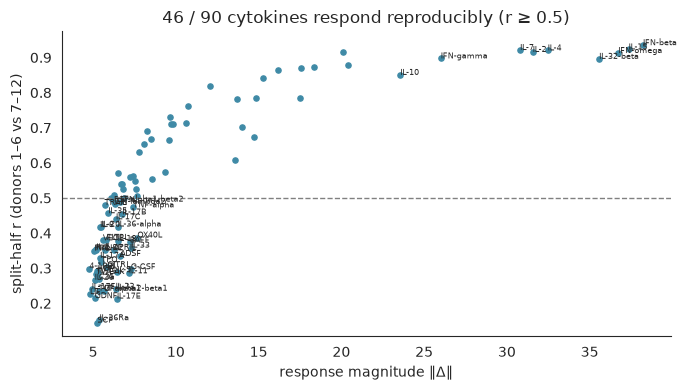

In [15]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(magnitude, reliability, s=14, color="#3F8AA6")
for c in ALL_CYT:
    if reliability[c] < RELIABLE_R or magnitude[c] > magnitude.quantile(0.9):
        ax.annotate(c, (magnitude[c], reliability[c]), fontsize=6)
ax.axhline(RELIABLE_R, color="0.5", ls="--", lw=1)
ax.set_xlabel("response magnitude ‖Δ‖"); ax.set_ylabel("split-half r (donors 1–6 vs 7–12)")
ax.set_title(f"{(reliability >= RELIABLE_R).sum()} / {len(ALL_CYT)} cytokines respond reproducibly (r ≥ {RELIABLE_R})")
sns.despine(); plt.tight_layout(); plt.show()

### A. Same 14 cytokines as part 3: response space next to ESM2 and the learned embedding

,silhouette,perm_mean,perm_95%,p_empirical
space,,,,
ESM2 (raw),0.097,-0.237,0.020,0.040
ESM2 (centred),0.139,-0.192,0.028,0.020
learned Donor1,-0.128,-0.220,-0.059,0.158
learned Donor12,-0.207,-0.212,-0.065,0.416
learned Donor2,-0.030,-0.210,-0.028,0.069
learned Donor8,-0.296,-0.236,-0.057,0.733
learned donor-mean,-0.117,-0.208,-0.046,0.168
response (data),-0.021,-0.132,-0.010,0.099


,Common γ chain/IL-13/TSLP,Growth factor,IL-6/IL-12,TNF
ESM2 (raw),0.361,-0.507,-0.295,0.036
ESM2 (centred),0.360,-0.402,-0.360,0.295
learned Donor1,0.036,-0.482,-0.141,-0.419
learned Donor12,-0.173,-0.387,0.283,-0.651
learned Donor2,-0.043,-0.400,0.727,-0.368
learned Donor8,-0.220,-0.467,-0.447,-0.275
learned donor-mean,0.025,-0.495,0.255,-0.677
response (data),0.015,-0.330,0.354,-0.229


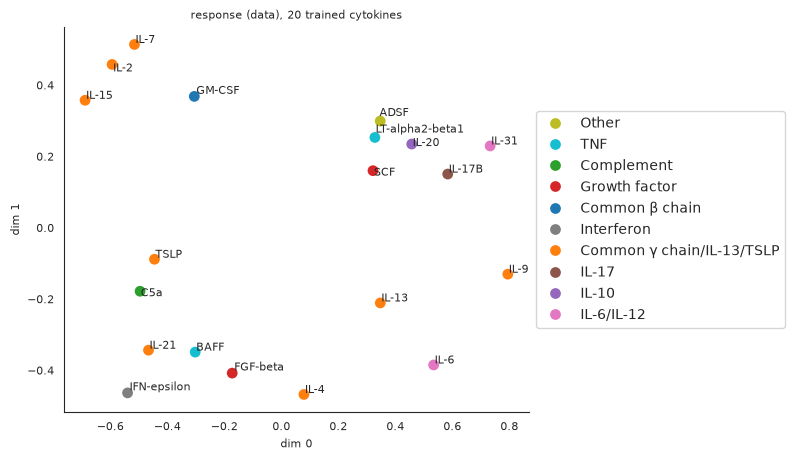

In [16]:
s, null = silhouette_test(RESP.loc[multi.index].values, multi.values)
nulls["response (data)"] = null
sil.loc["response (data)"] = pd.Series({"silhouette": s, "perm_mean": null.mean(), "perm_95%": np.quantile(null, 0.95),
                                        "p_empirical": (1 + (null >= s).sum()) / (1 + N_PERM)})
D = squareform(pdist(RESP.loc[multi.index].values, "cosine"))
per_fam["response (data)"] = pd.Series(silhouette_samples(D, multi.values, metric="precomputed"), index=multi.index) \
    .groupby(multi.values).mean()
display(sil.round(3))
display(pd.DataFrame(per_fam).T.round(3))
plot_space("response (data), 20 trained cytokines", RESP.loc[TRAINED])

### B. All 90 cytokines

In [17]:
fam90 = pb.obs.drop_duplicates("cytokine").set_index("cytokine")["cytokine_family"].astype(str).reindex(ALL_CYT)
lab90 = fam90[~fam90.isin(CATCH_ALL) & (fam90 != "nan")]
lab90 = lab90[lab90.map(lab90.value_counts()) >= 2]
print(f"{len(lab90)} cytokines in {lab90.nunique()} families:", lab90.value_counts().to_dict())

SPACES90 = {"response (data)": RESP, "ESM2 (raw)": esm2_df, "ESM2 (centred)": esm2_centred,
            "learned donor-mean": learned["donor-mean"]}


def sil_table(labels, spaces):
    rows, nl = [], {}
    for name, X in spaces.items():
        s, null = silhouette_test(X.loc[labels.index].values, labels.values)
        nl[name] = null
        rows.append({"space": name, "n_cytokines": len(labels), "silhouette": s, "perm_mean": null.mean(),
                     "perm_95%": np.quantile(null, 0.95), "p_empirical": (1 + (null >= s).sum()) / (1 + N_PERM)})
    return pd.DataFrame(rows).set_index("space"), nl


sil90, nulls90 = sil_table(lab90, SPACES90)
reliable = reliability[reliability >= RELIABLE_R].index
lab90r = lab90[lab90.index.isin(reliable)]
lab90r = lab90r[lab90r.map(lab90r.value_counts()) >= 2]
sil90r, _ = sil_table(lab90r, SPACES90)
display(sil90.round(3))
print(f"reliably responding cytokines only (split-half r ≥ {RELIABLE_R}):")
display(sil90r.round(3))

77 cytokines in 10 families: {'TNF': 17, 'Growth factor': 11, 'IL-6/IL-12': 10, 'Interferon': 8, 'Common γ chain/IL-13/TSLP': 8, 'IL-1': 7, 'IL-17': 6, 'IL-10': 5, 'Common β chain': 3, 'Complement': 2}


,n_cytokines,silhouette,perm_mean,perm_95%,p_empirical
space,,,,,
response (data),77,-0.118,-0.182,-0.154,0.01
ESM2 (raw),77,-0.142,-0.246,-0.182,0.01
ESM2 (centred),77,-0.020,-0.195,-0.161,0.01
learned donor-mean,77,-0.191,-0.353,-0.260,0.01


reliably responding cytokines only (split-half r ≥ 0.5):


,n_cytokines,silhouette,perm_mean,perm_95%,p_empirical
space,,,,,
response (data),40,-0.058,-0.208,-0.160,0.01
ESM2 (raw),40,-0.211,-0.276,-0.218,0.04
ESM2 (centred),40,-0.080,-0.223,-0.184,0.01
learned donor-mean,40,-0.120,-0.328,-0.266,0.01


In [18]:
per_fam90 = {}
for name, X in SPACES90.items():
    D = squareform(pdist(X.loc[lab90.index].values, "cosine"))
    per_fam90[name] = pd.Series(silhouette_samples(D, lab90.values, metric="precomputed"), index=lab90.index) \
        .groupby(lab90.values).mean()
pd.DataFrame(per_fam90).T.round(3)

,Common β chain,Common γ chain/IL-13/TSLP,Complement,Growth factor,IL-1,IL-10,IL-17,IL-6/IL-12,Interferon,TNF
response (data),-0.058,-0.152,-0.386,-0.201,-0.150,-0.120,-0.024,-0.228,0.244,-0.153
ESM2 (raw),0.537,-0.514,0.693,-0.430,0.070,0.172,0.257,-0.165,-0.296,-0.233
ESM2 (centred),0.392,-0.426,0.849,-0.257,0.097,0.134,0.392,-0.037,-0.193,0.004
learned donor-mean,-0.149,-0.324,0.891,-0.511,-0.408,-0.464,0.654,0.288,-0.423,-0.355


Where does family structure live? The response-space silhouette on each cell type's delta alone (all 90 cytokines,
same labels).

In [19]:
ct_rows = []
for ct in RESP_CT:
    s, null = silhouette_test(RESP[ct].loc[lab90.index].values, lab90.values)
    ct_rows.append({"cell_type": ct, "silhouette": s, "perm_95%": np.quantile(null, 0.95),
                    "p_empirical": (1 + (null >= s).sum()) / (1 + N_PERM)})
pd.DataFrame(ct_rows).set_index("cell_type").sort_values("silhouette", ascending=False).round(3)

,silhouette,perm_95%,p_empirical
cell_type,,,
cDC,-0.100,-0.135,0.010
NKT,-0.117,-0.126,0.030
CD16 Mono,-0.124,-0.161,0.010
NK CD56bright,-0.130,-0.151,0.010
CD14 Mono,-0.131,-0.166,0.010
Treg,-0.159,-0.155,0.099
MAIT,-0.159,-0.174,0.010
B Intermediate/Memory,-0.171,-0.177,0.040
B Naive,-0.179,-0.202,0.020


### C. Shared-receptor groups, all four spaces on the same 90 cytokines

In [20]:
rows = []
for gname, members in RECEPTOR_GROUPS.items():
    for name, X in SPACES90.items():
        w, b, pct = group_stats(X.loc[ALL_CYT], members, ALL_CYT)
        rows.append({"group": gname, "space": name, "within": w, "between": b, "ratio": w / b, "percentile": pct})
groups90 = pd.DataFrame(rows)
display(groups90.pivot(index="group", columns="space", values="ratio").loc[list(RECEPTOR_GROUPS), list(SPACES90)].round(2))
display(groups90.pivot(index="group", columns="space", values="percentile").loc[list(RECEPTOR_GROUPS), list(SPACES90)].round(1))
print("split-half reliability of group members:")
pd.Series({m: round(reliability[m], 2) for g in RECEPTOR_GROUPS.values() for m in g})

space,response (data),ESM2 (raw),ESM2 (centred),learned donor-mean
group,,,,
CSF1R,0.69,0.45,0.42,0.53
IFNAR,0.42,0.35,0.40,0.56
gp130,1.10,0.49,0.60,0.28
IL17RA/RC,0.81,0.12,0.16,0.03


space,response (data),ESM2 (raw),ESM2 (centred),learned donor-mean
group,,,,
CSF1R,21.8,9.8,3.6,26.7
IFNAR,0.1,0.2,0.0,14.4
gp130,84.2,0.4,0.1,1.7
IL17RA/RC,23.1,0.2,0.3,0.1


split-half reliability of group members:


M-CSF          0.79
IL-34          0.65
IFN-alpha1     0.78
IFN-beta       0.94
IFN-epsilon    0.76
IFN-omega      0.91
IL-6           0.71
IL-11          0.29
LIF            0.23
OSM            0.57
CT-1           0.71
IL-17A         0.33
IL-17F         0.24
dtype: float64

### The comparison in one figure

Left: family silhouette (all 90 cytokines) against 100 label permutations in each space. Right: how tight each
shared-receptor group is (percentile of its within-group distance among random groups of the same size; lower =
tighter; ≤ 5 is marked).

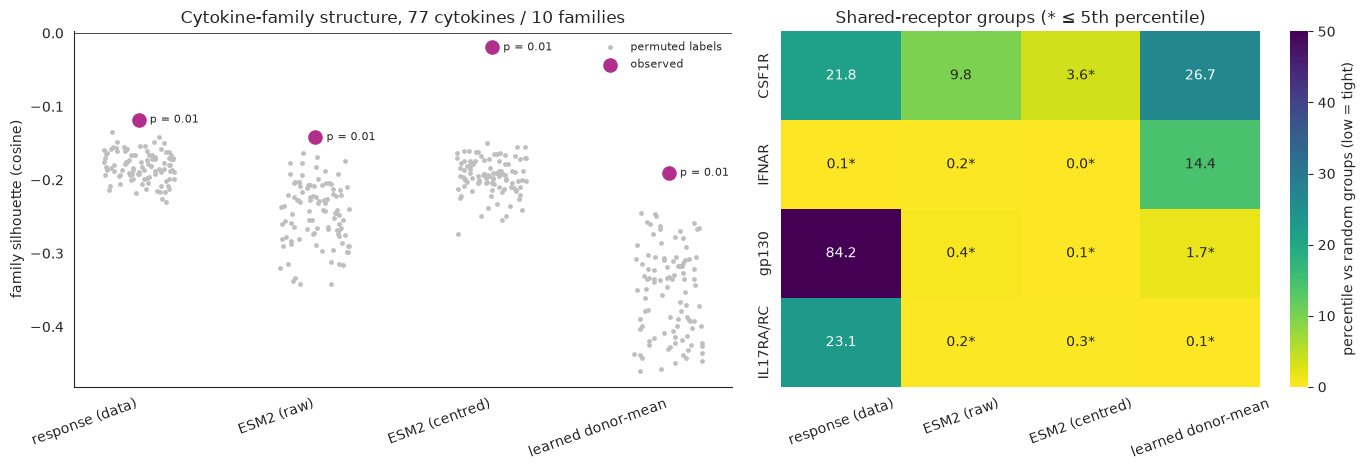

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1.1, 1]})
ax = axes[0]
order90 = list(SPACES90)
for i, name in enumerate(order90):
    ax.scatter(np.full(N_PERM, i) + np.random.default_rng(i).uniform(-0.2, 0.2, N_PERM), nulls90[name],
               s=6, color="0.75", label="permuted labels" if i == 0 else None)
    ax.scatter(i, sil90.loc[name, "silhouette"], s=90, color="#B12F8C", zorder=3, label="observed" if i == 0 else None)
    ax.annotate(f"p = {sil90.loc[name, 'p_empirical']:.2f}", (i, sil90.loc[name, "silhouette"]),
                xytext=(8, 0), textcoords="offset points", va="center", fontsize=8)
ax.axhline(0, color="k", lw=0.5)
ax.set_xticks(range(len(order90)), order90, rotation=20, ha="right")
ax.set_ylabel("family silhouette (cosine)")
ax.set_title(f"Cytokine-family structure, {len(lab90)} cytokines / {lab90.nunique()} families")
ax.legend(frameon=False, fontsize=8)

pct = groups90.pivot(index="group", columns="space", values="percentile").loc[list(RECEPTOR_GROUPS), order90]
sns.heatmap(pct, annot=pct.round(1).astype(str) + np.where(pct <= 5, "*", ""), fmt="", cmap="viridis_r",
            vmin=0, vmax=50, ax=axes[1], cbar_kws={"label": "percentile vs random groups (low = tight)"})
axes[1].set_title("Shared-receptor groups (* ≤ 5th percentile)")
axes[1].set_xlabel(""); axes[1].set_ylabel("")
axes[1].tick_params(axis="x", rotation=20)
sns.despine(ax=axes[0])
plt.tight_layout()
plt.savefig("../models/07_response_vs_embedding_structure.png", dpi=200, bbox_inches="tight")
plt.show()

## Conclusion — Part II (response space)

**Neither clean outcome. PBMC responses have only weak cytokine-family structure. The one strong receptor signal in
the data is the type I interferons (IFNAR), and even there the comparison with the model is confounded.**

1. **Half of the cytokines barely do anything reproducible.** Only 40 of 90 have a response vector that replicates
   between donor halves (split-half r ≥ 0.5). The rest (SCF, GDNF, LIF, IL-17F, TGF-β1, …) have small, noisy responses.
   Most of the "family" labels therefore sit on top of near-null responses. This fits the receptor-competence premise
   of notebook 09, but it means family clustering can only ever be carried by the responsive half.
2. **Family structure in responses is real but weak.** Over 77 cytokines in 10 families, the response-space
   silhouette is −0.12 against a permutation mean of −0.18 (p = 0.01, the smallest possible with 100 permutations).
   Restricted to the 40 reliable responders, it is −0.06 vs −0.21 (p = 0.01). Families overlap heavily. Only the
   **interferons** cohere (per-family silhouette +0.24); every other family is negative. On the 14 trained cytokines
   (comparison A) the response silhouette is not significant (p = 0.10).
3. **ESM2 and the learned embedding show about as much family structure, but in different families.** Both also
   beat permutations over the 77 cytokines (p = 0.01). ESM2 groups sequence families (complement, common β chain,
   IL-17), and the learned embedding groups complement, IL-17 and IL-6/IL-12. The interferons, the only family that
   coheres in the cells, are *not* grouped in either embedding (−0.30 / −0.42).
4. **Shared-receptor groups** (percentile of within-group distance vs random groups; low = tight):

   | group | response (data) | ESM2 (centred) | learned |
   |---|---|---|---|
   | IFNAR | **0.1** | 0.0 | 14.4 |
   | CSF1R | 21.8 | 3.6 | 26.7 |
   | gp130 | 84.2 | 0.1 | 1.7 |
   | IL17RA/RC | 23.1 | 0.3 | 0.1 |

   * **IFNAR is the one group that is tight in the cells.** IFN-α1, -β, -ε and -ω all respond strongly and alike. ESM2
     also groups them, but the learned embedding loosens them (14th percentile). *However*, only IFN-ε was in training,
     so this is not a fair "failed to learn" test.
   * **gp130 is the opposite case.** ESM2 and the model keep these cytokines tight, but the cells do not respond alike
     (84th percentile). The shared gp130 chain is not what decides a PBMC response: the ligand-specific α chains are.
     IL-11 and LIF responses barely replicate (r = 0.29, 0.23), consistent with low IL11RA/LIFR in blood. The same holds
     for IL-17A/F (unreliable responses, tight in ESM2).
   * **M-CSF and IL-34** both respond reproducibly (r = 0.79, 0.65) but are not unusually similar (22nd percentile),
     even though they share CSF1R.
5. **Where structure exists, it is myeloid.** Per-cell-type silhouettes pass permutations mainly in cDC, CD16/CD14 monocytes and
   NK CD56bright. Naive CD4 T cells show none (p = 0.20).

**Plain-language summary.** In PBMCs, "same receptor family" does not generally mean "same response". What decides
the response is whether the cells carry the ligand-specific receptor chain, and many don't. ESM2, and through it the
model, encodes *sequence* families. Those families match the biology for the interferons and mismatch it for gp130 and
IL-17. So the premise needs narrowing: receptor structure is visible in the data only where the full receptor is
expressed on blood cells (IFNAR). The motivating figure is therefore **not** "responses cluster by family, embeddings
don't". It is closer to: *"the embedding groups by sequence family; the cells group by functional receptor
availability; the two agree only for IFNAR."* The clean model-side version of that panel needs a model trained with
the IFNAR and gp130 members in the training set.

Figure: `models/07_response_vs_embedding_structure.png`.
